# 第8章：把决策树完整算出来

**教师参考｜全书深化稿**

## 背景与数据
十点分类、六点回归和九点网格是人工算例；真实鸢尾花的树图和表使用同一90/30开发划分。

## 本次要回答的问题
全枚举分类阈值、核对回归SSE、验证贪心反例，再生成深度和剪枝结果。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 8: corrected split enumeration, greedy counterexample and pruning."""
import numpy as np
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor,export_text,plot_tree
from sklearn.metrics import accuracy_score,mean_squared_error
from common import *

def impurity(y):
    if not len(y):return 0.
    p=np.bincount(np.asarray(y,dtype=int),minlength=2)/len(y)
    return 1-float(p@p)

def run():
    x=np.array([1.,1.6,2.,2.4,2.8,3.,3.4,3.6,4.2,5.]);y=np.array([0,0,0,0,0,1,0,1,1,1]);rows=[]
    for t in (x[:-1]+x[1:])/2:
        L=y[x<=t];R=y[x>t];weighted=(len(L)*impurity(L)+len(R)*impurity(R))/len(y)
        rows.append({'threshold':t,'left_n':len(L),'right_n':len(R),'weighted_gini':weighted,'gain':impurity(y)-weighted})
    df=table('ch08_split_search',rows);assert np.isclose(df.loc[df.gain.idxmax(),'threshold'],2.9);show_result(df)
    plt.figure(figsize=(6.4,4));plt.plot(df.threshold,df.gain,'o-');plt.xlabel('候选中点阈值');plt.ylabel('Gini下降');figure('v3_ch08_candidates')
    # Counterexample: all comparisons use the same max-depth limit.
    grid=np.array([[i,j] for i in [1,2,3] for j in [1,2,3]])
    labels=np.array([0,0,0,0,0,1,1,1,1]);m=DecisionTreeClassifier(max_depth=2,random_state=42).fit(grid,labels)
    alt=np.where(grid[:,1]<=2.5,np.where(grid[:,0]<=2.5,0,1),np.where(grid[:,0]<=1.5,0,1))
    assert np.sum(m.predict(grid)!=labels)==1 and np.sum(alt!=labels)==0
    dump('ch08_greedy',{'greedy_errors':int(np.sum(m.predict(grid)!=labels)),'alternative_errors':int(np.sum(alt!=labels)),
       'greedy_tree':export_text(m,feature_names=['x1','x2'])})
    plt.figure(figsize=(7,4));plot_tree(m,feature_names=['x1','x2'],class_names=['A','B'],filled=False,rounded=True,fontsize=9);figure('v3_ch08_greedy_tree')
    Xtr,Xva,ytr,yva,ds=development_trainval('iris');rows=[]
    for depth in [1,2,3,4,6,None]:
        t=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(Xtr,ytr)
        rows.append({'max_depth':str(depth),'leaves':t.get_n_leaves(),'training_accuracy':t.score(Xtr,ytr),'validation_accuracy':t.score(Xva,yva)})
    df=table('ch08_iris_depth',rows);show_result(df)
    t=DecisionTreeClassifier(max_depth=2,random_state=42).fit(Xtr,ytr)
    plt.figure(figsize=(9,5));plot_tree(t,feature_names=ds.feature_names,class_names=ds.target_names,filled=False,rounded=True,fontsize=9);figure('v3_ch08_iris_tree')
    sample=Xva.iloc[[0]];path=t.decision_path(sample).indices
    dump('ch08_iris_path',{'row_id':int(sample.index[0]),'values':sample.iloc[0].to_dict(),'true':int(yva.iloc[0]),'predicted':int(t.predict(sample)[0]),'probability':t.predict_proba(sample)[0],'nodes':path,'tree':export_text(t,feature_names=ds.feature_names)})
    # Fixed alpha grid, not selected using held-out test outcomes.
    rows=[]
    for alpha in [0,.005,.01,.02,.04,.08,.16]:
        t=DecisionTreeClassifier(ccp_alpha=alpha,random_state=42).fit(Xtr,ytr)
        rows.append({'alpha':alpha,'leaves':t.get_n_leaves(),'train_accuracy':t.score(Xtr,ytr),'validation_accuracy':t.score(Xva,yva)})
    df=table('ch08_pruning',rows)
    plt.figure(figsize=(6.4,4));plt.plot(df.alpha,df.train_accuracy,'o-',label='training');plt.plot(df.alpha,df.validation_accuracy,'s-',label='validation');plt.xlabel('ccp_alpha');plt.ylabel('准确率');plt.legend();figure('v3_ch08_pruning')
    # Regression demonstration is explicitly synthetic, never labelled housing data.
    xr=np.arange(1,7,dtype=float);yr=np.array([1.,2.,3.,7.,8.,9.]);rows=[]
    for split in xr[:-1]+.5:
        a=yr[xr<=split];b=yr[xr>split];sse=np.sum((a-a.mean())**2)+np.sum((b-b.mean())**2)
        rows.append({'threshold':split,'left_mean':a.mean(),'right_mean':b.mean(),'SSE':sse,'variance_reduction':np.var(yr)-sse/6})
    table('ch08_regression_splits',rows)
    r=DecisionTreeRegressor(max_depth=1,random_state=42).fit(xr[:,None],yr);xx=np.linspace(-1,8,300)
    plt.figure(figsize=(6.4,4));plt.scatter(xr,yr,label='artificial records');plt.plot(xx,r.predict(xx[:,None]),label='one split');plt.xlabel('人工输入 x');plt.ylabel('人工目标 y');plt.legend();figure('v3_ch08_regression')

In [3]:
result = run()
if result is not None:
    print(result)

 threshold  left_n  right_n  weighted_gini     gain
       1.3       1        9       0.444444 0.035556
       1.8       2        8       0.400000 0.080000
       2.2       3        7       0.342857 0.137143
       2.6       4        6       0.266667 0.213333
       2.9       5        5       0.160000 0.320000
       3.2       6        4       0.316667 0.163333
       3.5       7        3       0.171429 0.308571
       3.9       8        2       0.300000 0.180000
       4.6       9        1       0.400000 0.080000


max_depth  leaves  training_accuracy  validation_accuracy
        1       2           0.666667             0.666667
        2       3           0.966667             0.933333
        3       4           0.988889             0.966667
        4       5           1.000000             0.966667
        6       5           1.000000             0.966667
     None       5           1.000000             0.966667


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch08_candidates.png


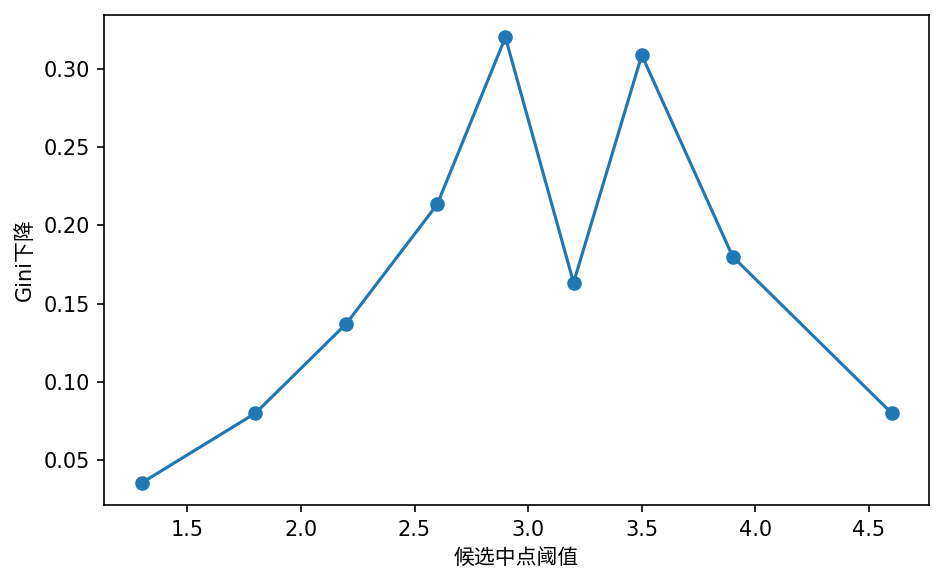

v3_ch08_greedy_tree.png


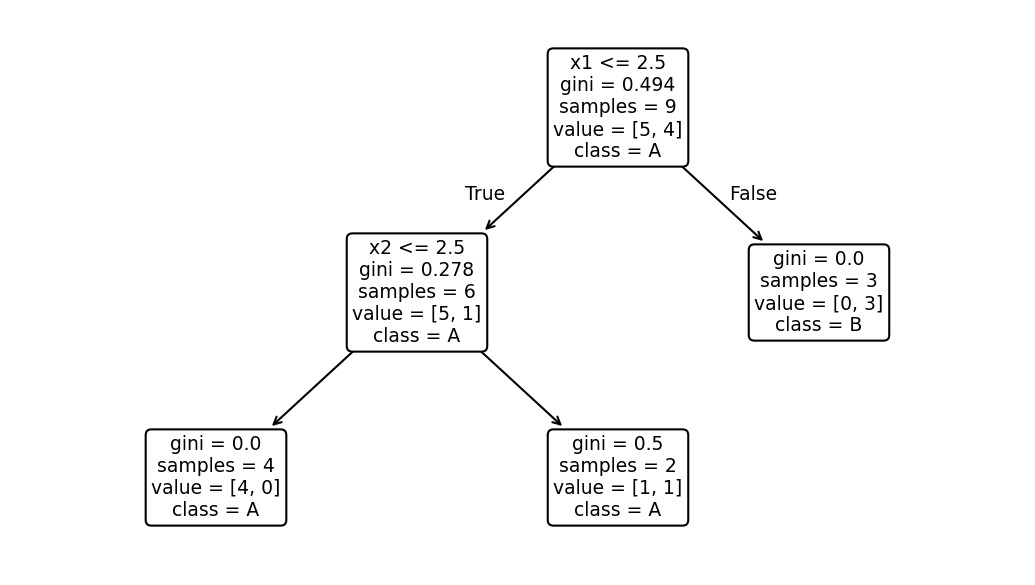

v3_ch08_iris_tree.png


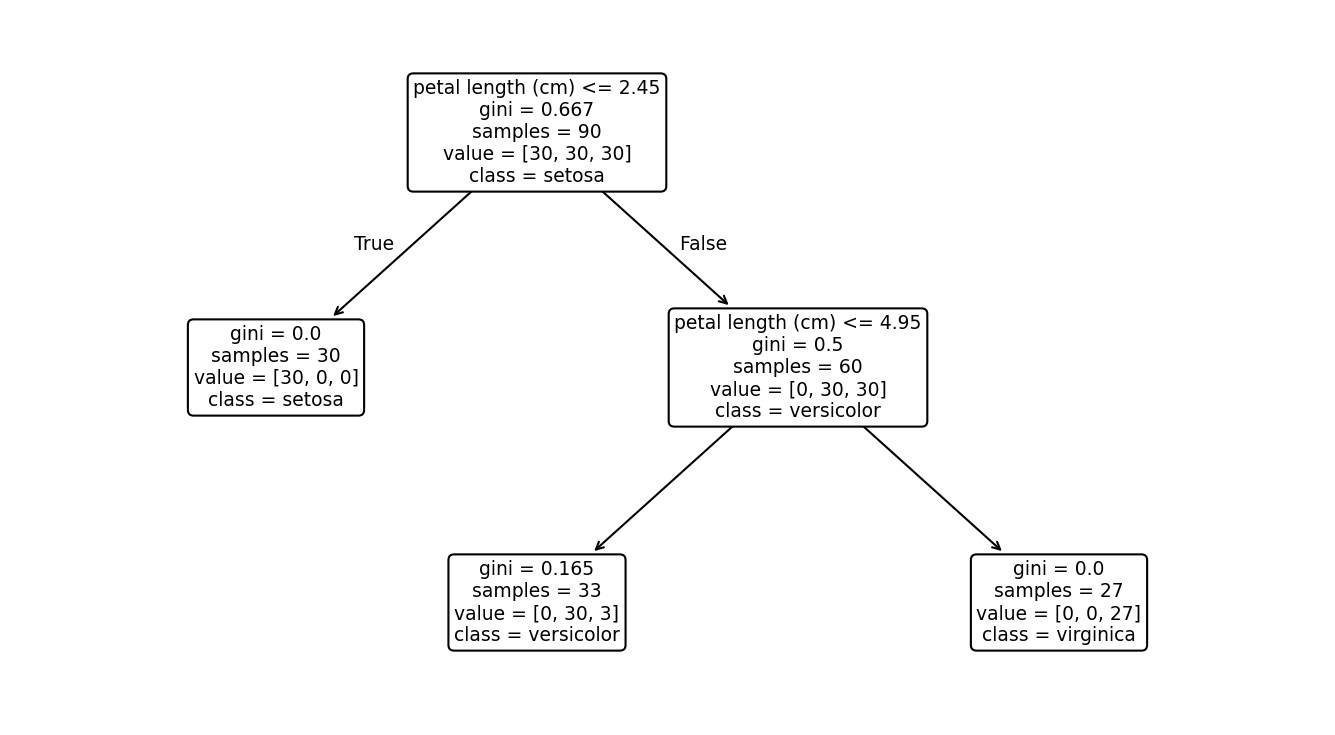

v3_ch08_pruning.png


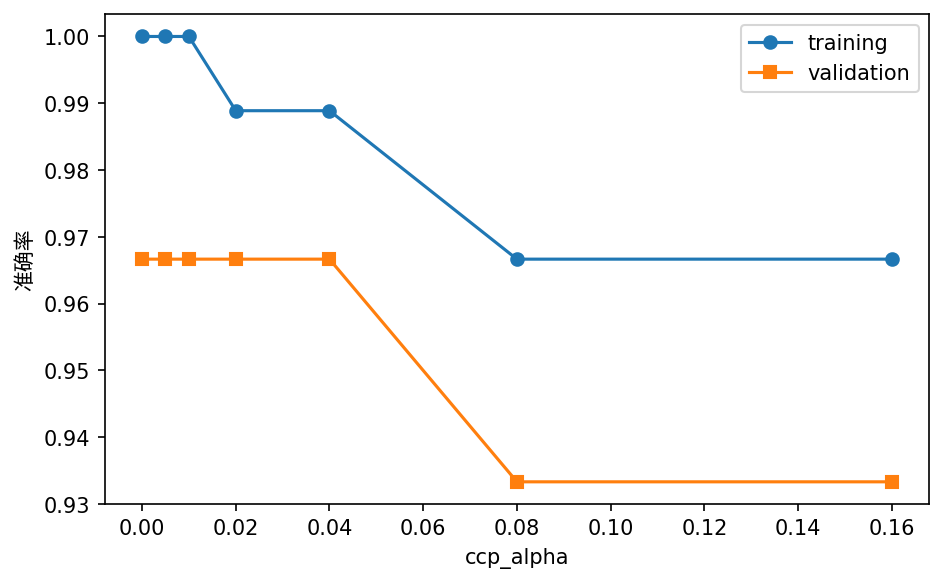

v3_ch08_regression.png


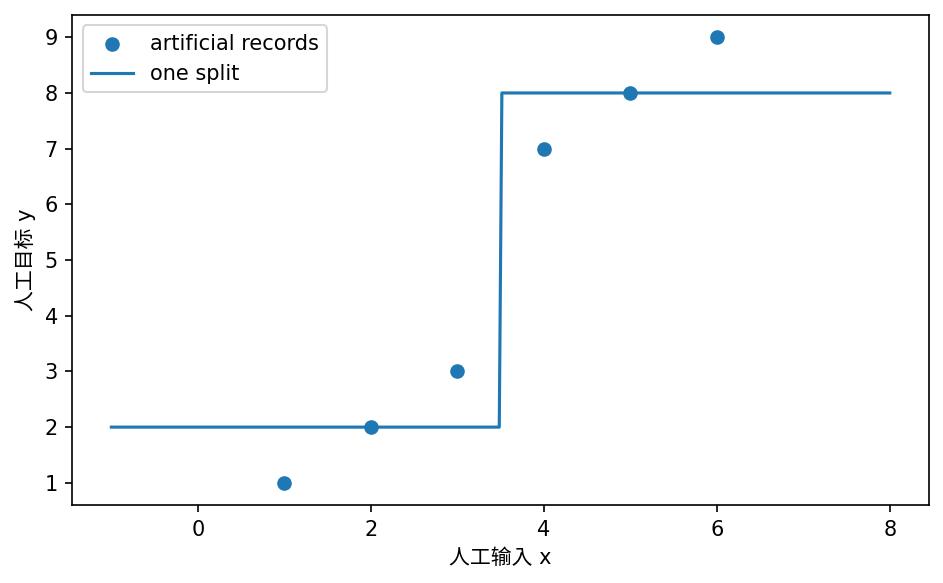

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch08_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

最佳分类中点为2.9；两候选比较不能声称全局枚举最优。验证曲线平台是实际结果，不强行解释为已发生下降。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。